# CSE620 Final Project
## Vision Transformer (ViT) for Image Classification

| | |
|---|---|
| **Course** | CSE620 |
| **Date** | 10/21/2026 |
| **Presenters** | Van Q. Phung, Wanling Jiang |
| **Tools** | Python, PyTorch, torchvision, matplotlib, scikit-learn |
| **Dataset** | CIFAR-10 (public, loaded through `torchvision`) |

#

#Live Demo

In [ ]:
# Mount Google Drive to access checkpoint files
from google.colab import drive
drive.mount('/content/drive')

# Optional: After mounting, if your 'vit_cifar10.pt' is in a specific folder in your Drive,
# you can copy it to the local working directory so the notebook finds it:
# !cp /content/drive/MyDrive/path_to_your_folder/vit_cifar10.pt .

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# LIVE DEMO 1/3 — Fast setup: imports, fixed model configuration, and checkpoint preflight
import os, math, time, random, hashlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

CFG = dict(IMG_SIZE=32, PATCH_SIZE=4, DIM=192, DEPTH=6, HEADS=6,
           MLP_RATIO=4, DROP=0.1, CKPT="vit_cifar10.pt")
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_file = Path('/content/drive/MyDrive/Colab Notebooks/CSE620 Deep Learning with PyTorch_September/CSE620_10min_Final Project ViT/vit_cifar10.pt')
assert checkpoint_file.is_file(), (
    "Missing vit_cifar10.pt. Upload it beside the notebook in Colab/VS Code "
    "before starting the demo. Do not retrain."
)
CFG["CKPT"] = str(checkpoint_file)  # Single source of truth for all subsequent checkpoint reads.
print("DEMO READY: checkpoint found | device:", device)


DEMO READY: checkpoint found | device: cuda


In [ ]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_chans=3, dim=192):
        super().__init__()
        assert img_size % patch_size == 0, "image size must be divisible by patch size"
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_chans, dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):                      # (B, 3, H, W)
        x = self.proj(x)                       # (B, D, H/P, W/P)
        return x.flatten(2).transpose(1, 2)    # (B, N, D)


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, dim, heads, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        assert dim % heads == 0
        self.h, self.dk = heads, dim // heads
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.attn_drop, self.proj_drop = nn.Dropout(attn_drop), nn.Dropout(proj_drop)

    def forward(self, x, return_attn=False):   # (B, N, D)
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.h, self.dk).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]                       # each (B, h, N, dk)
        attn = (q @ k.transpose(-2, -1)) / math.sqrt(self.dk)  # (B, h, N, N)
        attn = attn.softmax(dim=-1)
        out = (self.attn_drop(attn) @ v).transpose(1, 2).reshape(B, N, D)
        out = self.proj_drop(self.proj(out))
        return (out, attn) if return_attn else out


class EncoderBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4, drop=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = MultiHeadSelfAttention(dim, heads, drop, drop)
        self.norm2 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, hidden), nn.GELU(), nn.Dropout(drop),
                                 nn.Linear(hidden, dim), nn.Dropout(drop))

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))


class ViT(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_chans=3, num_classes=10,
                 dim=192, depth=6, heads=6, mlp_ratio=4, drop=0.1):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_chans, dim)
        n = self.patch_embed.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n + 1, dim))
        self.pos_drop = nn.Dropout(drop)
        self.blocks = nn.ModuleList([EncoderBlock(dim, heads, mlp_ratio, drop) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def embed(self, x):
        x = self.patch_embed(x)                                # (B, N, D)
        cls = self.cls_token.expand(x.shape[0], -1, -1)        # (B, 1, D)
        x = torch.cat([cls, x], dim=1) + self.pos_embed        # (B, N+1, D)
        return self.pos_drop(x)

    def forward(self, x):
        x = self.embed(x)
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.norm(x)[:, 0])                   # classify from the [CLS] token

    @torch.no_grad()
    def cls_attention(self, x):
        # Attention paid by [CLS] to each patch in the last block, averaged over heads: (B, N)
        x = self.embed(x)
        for blk in self.blocks[:-1]:
            x = blk(x)
        last = self.blocks[-1]
        _, attn = last.attn(last.norm1(x), return_attn=True)
        return attn[:, :, 0, 1:].mean(dim=1)


model = ViT(CFG["IMG_SIZE"], CFG["PATCH_SIZE"], 3, len(CLASSES), CFG["DIM"],
            CFG["DEPTH"], CFG["HEADS"], CFG["MLP_RATIO"], CFG["DROP"]).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"ViT parameters: {n_params/1e6:.2f} M")

ViT parameters: 2.69 M


In [ ]:
# LIVE DEMO 2/3 — Load actual trained weights and CIFAR-10 test images.
# First run downloads CIFAR-10 (~170 MB); do this BEFORE presenting.
import torchvision
from torchvision import transforms as T

saved = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
saved_cfg = saved.get("cfg", {})
for k in ("IMG_SIZE", "PATCH_SIZE", "DIM", "DEPTH", "HEADS", "MLP_RATIO"):
    assert saved_cfg[k] == CFG[k], f"Checkpoint/model mismatch: {k}"
model.load_state_dict(saved["model"], strict=True)
model.eval()
print(f"PASS: loaded {sum(p.numel() for p in model.parameters()):,} trained parameters")
print(f"Recorded best validation accuracy: {100*saved['best_val_acc']:.2f}%")

eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
test_ds = torchvision.datasets.CIFAR10(
    root="/content/drive/MyDrive/Colab Notebooks/CSE620 Deep Learning with PyTorch_September/CSE620_10min_Final Project ViT/data", train=False, download=True, transform=eval_tf
)
assert len(test_ds) == 10000
mean_t = torch.tensor(MEAN).view(3, 1, 1)
std_t = torch.tensor(STD).view(3, 1, 1)
def denorm(x):
    return (x.cpu() * std_t + mean_t).clamp(0, 1)
print("PASS: official CIFAR-10 test images ready (10,000 examples)")


PASS: loaded 2,693,578 trained parameters
Recorded best validation accuracy: 79.22%
PASS: official CIFAR-10 test images ready (10,000 examples)


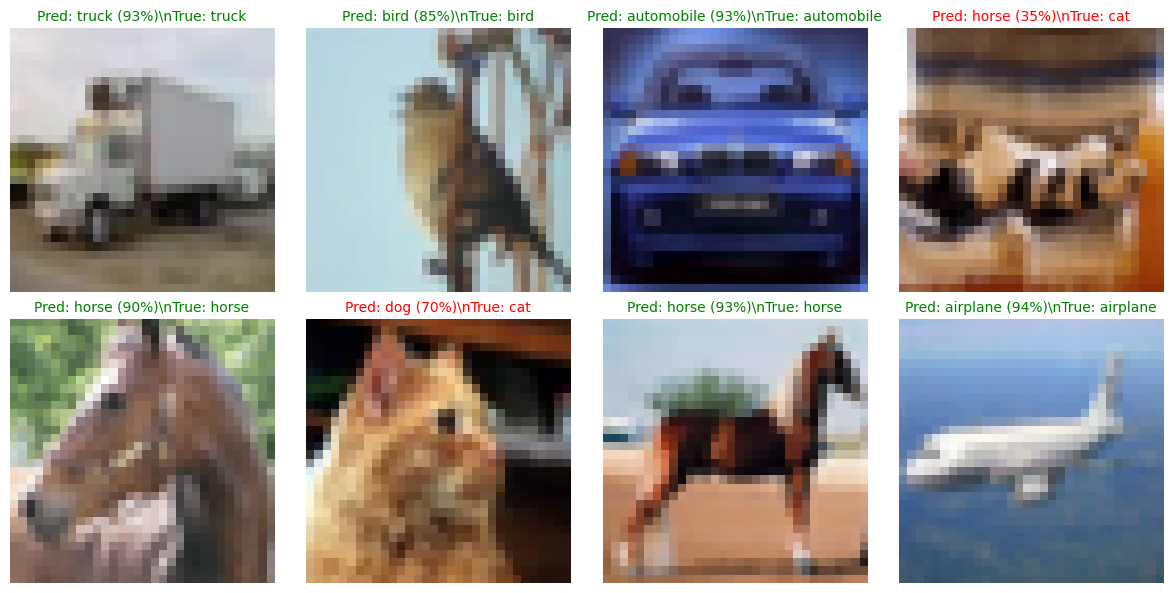

LIVE RESULT: 6/8 correct | 1909.5 ms for 8 images on cuda
Note: batch accuracy is illustrative; full test accuracy requires all 10,000 images.


In [ ]:
# LIVE DEMO 3/3 — Rerun this cell to prove real, fresh inference on unseen images.
@torch.no_grad()
def live_demo(n=8, seed=42):
    assert model.training is False, "Call model.eval() before inference"
    rng = random.Random(seed)
    ids = rng.sample(range(len(test_ds)), n)
    x = torch.stack([test_ds[i][0] for i in ids])
    labels = [test_ds[i][1] for i in ids]
    start = time.perf_counter()
    probabilities = torch.softmax(model(x.to(device)), dim=1).cpu()
    duration_ms = 1000 * (time.perf_counter() - start)
    confidence, predictions = probabilities.max(dim=1)
    cols = 4
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3.0 * rows))
    for ax, j in zip(np.asarray(axes).reshape(-1), range(n)):
        predicted, actual = int(predictions[j]), int(labels[j])
        ax.imshow(denorm(x[j]).permute(1, 2, 0))
        ax.set_title(f"Pred: {CLASSES[predicted]} ({confidence[j]:.0%})\\n"
                     f"True: {CLASSES[actual]}", color="green" if predicted == actual else "red", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    correct = sum(int(predictions[j]) == int(labels[j]) for j in range(n))
    print(f"LIVE RESULT: {correct}/{n} correct | {duration_ms:.1f} ms for {n} images on {device}")
    print("Note: batch accuracy is illustrative; full test accuracy requires all 10,000 images.")

live_demo(n=8, seed=42)
# For audience participation, change seed=42 to any other integer and rerun.


## 1. Problem Definition

**Task:** Classify 32x32 color images into one of 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).

**Why it matters:** Image classification is the base task behind many real applications, including visual inspection and defect detection in manufacturing, medical imaging, and autonomous systems.

**Question this project answers:** Can a pure Transformer, with no convolutional feature extractor, learn to classify images when the image is treated as a sequence of patch tokens?

**Success criteria:** Report test accuracy, show training and validation curves, show a confusion matrix, and run a live inference demo.

## 2. Solution: Vision Transformer (ViT)

The Vision Transformer adapts a Transformer encoder to image classification:

1. **Split** the image into fixed-size patches (here 4x4 pixels, giving 64 patches for a 32x32 image).
2. **Embed** each patch with a linear projection into a vector of size `DIM`.
3. **Prepend** a learnable `[CLS]` token and **add** learnable positional embeddings.
4. Pass the token sequence through **N Transformer encoder blocks** (multi-head self-attention + MLP, each with LayerNorm and residual connections).
5. Feed the final `[CLS]` vector to a **linear classification head**.

The model is implemented from scratch in PyTorch (`nn.Module`), including scaled dot-product multi-head attention.

## 3. Setup

**Run order:** Run all cells top to bottom. Set `CFG["RETRAIN"] = True` to retrain. If no checkpoint is present, the training cell trains before test evaluation. The 79.91% result shown in saved outputs is a historical result, independently reproducible only with the corresponding trained weights and data.


In [ ]:
# Extend the existing demo configuration for reproducible training/evaluation.
# Imports, architecture, device, and checkpoint are already initialized above.
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import confusion_matrix, classification_report

# ---- Configuration -------------------------------------------------------
CFG.update(
    BATCH_SIZE=128, EPOCHS=30, LR=1e-3, WEIGHT_DECAY=0.05,
    WARMUP_EPOCHS=3, LABEL_SMOOTHING=0.1,
    SEED=42, NUM_WORKERS=2, DATA_DIR="/content/drive/MyDrive/Colab Notebooks/CSE620 Deep Learning with PyTorch_September/CSE620_10min_Final Project ViT/data",
    RETRAIN=False,             # True = ignore an existing checkpoint and train again
    TRAIN_SUBSET=None,         # e.g. 5000 for a quick smoke test; None = full 45k train split
)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(CFG["SEED"])
use_amp = device.type == "cuda"
print("PyTorch:", torch.__version__, "| device:", device, "| mixed precision:", use_amp)


PyTorch: 2.11.0+cu130 | device: cuda | mixed precision: True


In [ ]:
# Environment fingerprint — run to record the active software and hardware.
import platform, sys, sklearn
print("Python:", sys.version.split()[0], "| Platform:", platform.platform())
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("Device:", device, "| CUDA available:", torch.cuda.is_available())
print("Checkpoint exists:", os.path.isfile(Path('/content/drive/MyDrive/Colab Notebooks/CSE620 Deep Learning with PyTorch_September/CSE620_10min_Final Project ViT/vit_cifar10.pt')))
print("Retraining disabled:", not CFG["RETRAIN"])
assert not CFG["RETRAIN"], "Final verification must not retrain the original model"

Python: 3.13.15 | Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
NumPy: 2.1.3 | scikit-learn: 1.6.1
Device: cuda | CUDA available: True
Checkpoint exists: True
Retraining disabled: True


## 4. Data: CIFAR-10

- 60,000 color images (32x32), 10 classes: 50,000 train and 10,000 test.
- The 50,000 training images are split into **45,000 train / 5,000 validation**. The 10,000 test images are used only for the final results.
- Training augmentation: random crop (padding 4) and horizontal flip. Images are normalized with the CIFAR-10 channel mean and standard deviation.

train 45000 | val 5000 | test 10000


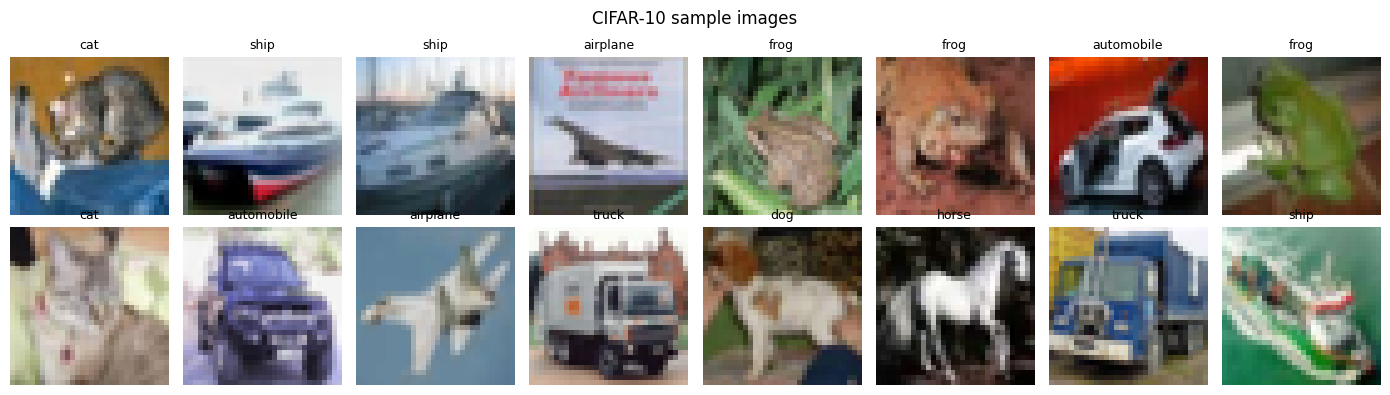

In [ ]:
# Reuse test_ds, eval_tf, denorm, and class names from the live demo.
train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(MEAN, STD)])

root = CFG["DATA_DIR"]
train_full = torchvision.datasets.CIFAR10(root, train=True, download=True, transform=train_tf)
val_full   = torchvision.datasets.CIFAR10(root, train=True, download=True, transform=eval_tf)
assert len(test_ds) == 10000  # reused from live demo setup

g = torch.Generator().manual_seed(CFG["SEED"])
perm = torch.randperm(len(train_full), generator=g).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]
if CFG["TRAIN_SUBSET"]:
    train_idx = train_idx[:CFG["TRAIN_SUBSET"]]
train_ds, val_ds = Subset(train_full, train_idx), Subset(val_full, val_idx)

loader_kw = dict(batch_size=CFG["BATCH_SIZE"], num_workers=CFG["NUM_WORKERS"], pin_memory=use_amp)
train_loader = DataLoader(train_ds, shuffle=True, drop_last=True, **loader_kw)
val_loader   = DataLoader(val_ds, shuffle=False, **loader_kw)
test_loader  = DataLoader(test_ds, shuffle=False, **loader_kw)
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")

# Sample images
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), range(16)):
    img, y = test_ds[i]
    ax.imshow(denorm(img).permute(1, 2, 0)); ax.set_title(CLASSES[y], fontsize=9); ax.axis("off")
plt.suptitle("CIFAR-10 sample images"); plt.tight_layout(); plt.show()

### Dataset partition integrity

The validation subset must be disjoint from training; the official CIFAR-10 test partition is separate. This is checked from the dataset indices without relying on any saved accuracy.

In [ ]:
# Verify exact split sizes and disjoint indices (training subset may be shortened for smoke tests).
assert len(val_ds) == 5000 and len(test_ds) == 10000
assert len(train_ds) <= 45000
train_ids, val_ids = set(train_ds.indices), set(val_ds.indices)
assert train_ids.isdisjoint(val_ids), "Training/validation overlap detected"
assert len(train_ids | val_ids) == len(train_ids) + len(val_ids)
print(f"PASS: {len(train_ds):,} training, {len(val_ds):,} validation, {len(test_ds):,} test samples; no train/validation overlap")

PASS: 45,000 training, 5,000 validation, 10,000 test samples; no train/validation overlap


### Images as sequences of patches

A 32x32 image with 4x4 patches becomes a sequence of **8 x 8 = 64 tokens**, each holding 4 x 4 x 3 = 48 raw values.

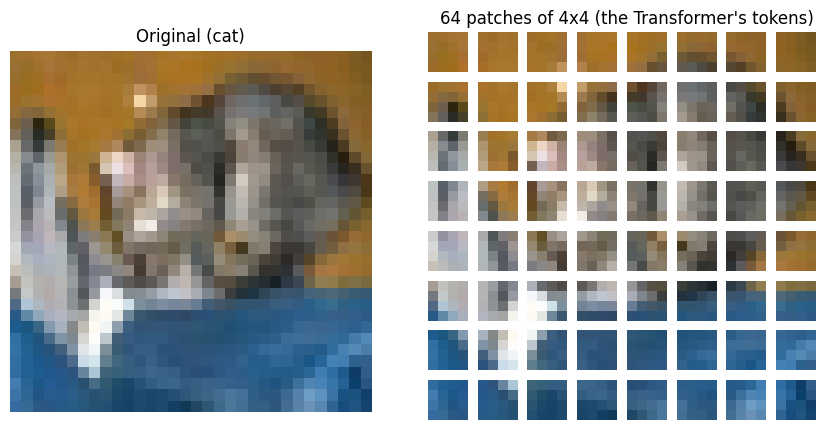

In [ ]:
img, y = test_ds[0]
P = CFG["PATCH_SIZE"]
patches = img.unfold(1, P, P).unfold(2, P, P)           # (3, 8, 8, P, P)
patches = patches.permute(1, 2, 0, 3, 4)                 # (8, 8, 3, P, P)
n = patches.shape[0]

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].imshow(denorm(img).permute(1, 2, 0)); axes[0].set_title(f"Original ({CLASSES[y]})"); axes[0].axis("off")
canvas = np.ones((n * (P + 1), n * (P + 1), 3))
for r in range(n):
    for c in range(n):
        canvas[r*(P+1):r*(P+1)+P, c*(P+1):c*(P+1)+P] = denorm(patches[r, c]).permute(1, 2, 0).numpy()
axes[1].imshow(canvas); axes[1].set_title(f"{n*n} patches of {P}x{P} (the Transformer's tokens)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## 5. Deep Learning: ViT Implementation in PyTorch

| Component | Role |
|---|---|
| `PatchEmbedding` | Splits the image into patches and projects each to a `DIM`-dimensional token (a `Conv2d` with kernel = stride = patch size is the same as a linear layer on flattened patches) |
| `MultiHeadSelfAttention` | Scaled dot-product attention: `softmax(QK^T / sqrt(d_k)) V`, computed in parallel over several heads |
| `EncoderBlock` | Pre-norm block: `x + MHSA(LN(x))`, then `x + MLP(LN(x))` |
| `ViT` | `[CLS]` token + positional embeddings + stack of encoder blocks + classification head |

**Architecture note:** This encoder uses bidirectional (unmasked) multi-head self-attention, positional embeddings, residual connections, and a learnable `[CLS]` classification token.

**Technical note:** `Conv2d(kernel_size=patch_size, stride=patch_size)` is used solely as a learnable patch projection. The attention display later shows **last-block, head-averaged `[CLS]`-to-patch weights**, *not* multi-layer attention rollout or proof of causal feature importance.


**Implementation note:** The ViT architecture is defined once in the executable demo cells above and reused here and throughout the analysis.


In [ ]:
# The ViT classes and trained `model` were defined in the executable demo above.
# Reuse that same instance here: no duplicate class definitions or reinitialization.
assert isinstance(model, ViT)
assert len(model.blocks) == CFG["DEPTH"]
n_params = sum(p.numel() for p in model.parameters())
print(f"ViT parameters: {n_params/1e6:.2f} M (shared with live demo)")

ViT parameters: 2.69 M (shared with live demo)


### Mathematical justification and computational complexity

For a normalized CIFAR-10 image \(x\in\mathbb{R}^{3\times32\times32}\), the learned convolutional patch projection uses kernel and stride \(P=4\). It produces \((32/4)^2=64\) image tokens, each in \(\mathbb{R}^{192}\). Adding one learnable classification token yields \(N=65\) tokens. The input tensor to each encoder block is therefore \([B,65,192]\).

Each attention head uses \(d_k=192/6=32\) features and computes

\[
\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V.
\]

The scaling factor controls the magnitude of dot products as the key/query dimension grows. The six attention heads learn separate projections; their outputs are concatenated and projected back to the model dimension. Pre-layer normalization, residual connections, and a GELU feed-forward network support optimization through the six encoder blocks. The final classifier uses only the normalized `[CLS]` representation.

**Why patch size matters:** self-attention forms an \(N\times N\) matrix per head, with \(O(N^2)\) attention storage and \(O(N^2d)\) attention arithmetic per layer (holding embedding dimension \(d\) fixed). At \(P=4\), the attention matrix has \(65^2=4{,}225\) elements per head per image; at \(P=8\), \(N=17\) and it has \(17^2=289\). This is an analytical comparison, **not a measured runtime or accuracy ablation**. The learned patch projection and feed-forward layers also contribute to total compute, so the matrix ratio must not be described as an end-to-end speedup.

Unlike an autoregressive decoder, this image-classification encoder uses **unmasked bidirectional self-attention**, allowing the `[CLS]` token to aggregate information from every image patch. The patch projection uses a convolution for tokenization; the encoder itself is attention-based.

### Architectural correctness checks (executable)

These assertions validate patch tokenization, output dimensions, attention normalization, finite logits, and the absence of causal masking. They run on a tiny synthetic batch and do not require retraining. They do **not** validate historical test accuracy.

In [ ]:
# Structural smoke tests: no CIFAR-10 samples or trained weights required.
assert CFG["IMG_SIZE"] % CFG["PATCH_SIZE"] == 0
assert CFG["DIM"] % CFG["HEADS"] == 0
assert len(model.blocks) == CFG["DEPTH"]
model.eval()
with torch.no_grad():
    probe = torch.randn(2, 3, CFG["IMG_SIZE"], CFG["IMG_SIZE"], device=device)
    tokens = model.patch_embed(probe)
    assert tokens.shape == (2, (CFG["IMG_SIZE"] // CFG["PATCH_SIZE"])**2, CFG["DIM"])
    logits = model(probe)
    assert logits.shape == (2, len(CLASSES)) and torch.isfinite(logits).all()
    attended, weights = model.blocks[0].attn(model.blocks[0].norm1(model.embed(probe)), return_attn=True)
    expected_n = tokens.shape[1] + 1
    assert weights.shape == (2, CFG["HEADS"], expected_n, expected_n)
    assert torch.allclose(weights.sum(-1), torch.ones_like(weights.sum(-1)), atol=1e-5)
    assert model.cls_attention(probe).shape == (2, expected_n - 1)
print("PASS: patch embeddings, ViT logits, encoder attention and CLS visualization shapes")

PASS: patch embeddings, ViT logits, encoder attention and CLS visualization shapes


### Tensor shape walkthrough

In [ ]:
model.eval()
x = torch.randn(2, 3, CFG["IMG_SIZE"], CFG["IMG_SIZE"], device=device)
with torch.no_grad():
    t = model.patch_embed(x);                                        print("1. patch embedding     :", tuple(x.shape), "->", tuple(t.shape))
    t = torch.cat([model.cls_token.expand(2, -1, -1), t], dim=1);    print("2. prepend [CLS]       :", "->", tuple(t.shape))
    t = t + model.pos_embed;                                         print("3. + position embed    :", "->", tuple(t.shape))
    for i, blk in enumerate(model.blocks):
        t = blk(t)
    print(f"4. after {len(model.blocks)} encoder blocks:", "->", tuple(t.shape))
    logits = model.head(model.norm(t)[:, 0]);                        print("5. [CLS] -> classifier :", "->", tuple(logits.shape))

1. patch embedding     : (2, 3, 32, 32) -> (2, 64, 192)
2. prepend [CLS]       : -> (2, 65, 192)
3. + position embed    : -> (2, 65, 192)
4. after 6 encoder blocks: -> (2, 65, 192)
5. [CLS] -> classifier : -> (2, 10)


### Training setup

- **Loss:** cross-entropy with label smoothing
- **Optimizer:** AdamW with weight decay, linear warm-up followed by cosine learning-rate decay
- **Regularization:** dropout, data augmentation, gradient clipping
- **Checkpointing:** the best validation model is saved to `vit_cifar10.pt`. If this file exists, it is loaded and training is skipped (set `RETRAIN=True` to train again).

In [ ]:
def build_scheduler(opt, steps_per_epoch):
    warm = CFG["WARMUP_EPOCHS"] * steps_per_epoch
    total = CFG["EPOCHS"] * steps_per_epoch
    def f(step):
        if step < warm:
            return (step + 1) / warm
        p = (step - warm) / max(1, total - warm)
        return 0.5 * (1 + math.cos(math.pi * p))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)


def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update(); scheduler.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

In [ ]:
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
ckpt_path = checkpoint_file  # Use the same trained checkpoint as the live demo.

if os.path.exists(ckpt_path) and not CFG["RETRAIN"]:
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=True)
    model.load_state_dict(ckpt["model"])
    history = ckpt.get("history", history)
    assert ckpt.get("cfg", {}).get("PATCH_SIZE", CFG["PATCH_SIZE"]) == CFG["PATCH_SIZE"], "Checkpoint patch size differs"
    print(f"Loaded checkpoint '{ckpt_path}' (best val acc {ckpt.get('best_val_acc', float('nan')):.4f}). Skipping training.")
else:
    print("No reusable checkpoint: training the model before evaluation.")
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG["LABEL_SMOOTHING"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
    scheduler = build_scheduler(optimizer, len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    best_val, t0 = 0.0, time.time()
    for epoch in range(1, CFG["EPOCHS"] + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scheduler, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
            history[k].append(v)
        if va_acc > best_val:
            best_val = va_acc
            torch.save({"model": model.state_dict(), "history": history,
                        "best_val_acc": best_val, "cfg": CFG}, ckpt_path)
        print(f"epoch {epoch:02d}/{CFG['EPOCHS']} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.0f}s")
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=True)       # restore the best model
    model.load_state_dict(ckpt["model"])
    print(f"Training done. Best val acc {best_val:.4f}. Checkpoint saved to '{ckpt_path}'.")

Loaded checkpoint '/content/drive/MyDrive/Colab Notebooks/CSE620 Deep Learning with PyTorch_September/CSE620_10min_Final Project ViT/vit_cifar10.pt' (best val acc 0.7922). Skipping training.


### Checkpoint provenance and reproducibility audit

The following checks read the **supplied trained checkpoint** rather than training a new model. They validate the checkpoint configuration, parameter tensors, and saved training history against the instantiated ViT. A successful check establishes weight/architecture compatibility; **it does not establish test-set accuracy**, which requires a separate inference pass over all 10,000 CIFAR-10 test images.

The SHA-256 digest identifies the exact checkpoint used. The saved historical training output was generated in a different run; it is retained unchanged for traceability.

In [ ]:
# Executable checkpoint audit: no CIFAR-10 download or retraining required.
import hashlib
from pathlib import Path

audit_path = checkpoint_file  # Same checkpoint as live demo and training-history analysis.
if not audit_path.is_file():
    print("CHECKPOINT NOT FOUND: supply vit_cifar10.pt to run the weight audit.")
else:
    audited = torch.load(audit_path, map_location="cpu", weights_only=True)
    saved_cfg = audited["cfg"]
    for key in ("IMG_SIZE", "PATCH_SIZE", "DIM", "DEPTH", "HEADS", "MLP_RATIO"):
        assert saved_cfg[key] == CFG[key], f"Architecture mismatch: {key}"
    current_state = model.state_dict()
    saved_state = audited["model"]
    assert set(saved_state) == set(current_state), "Parameter-key mismatch"
    assert all(saved_state[k].shape == current_state[k].shape for k in current_state), "Tensor-shape mismatch"
    h_audit = audited["history"]
    assert all(len(h_audit[k]) == saved_cfg["EPOCHS"] for k in
               ("train_loss", "val_loss", "train_acc", "val_acc"))
    recorded_best = max(h_audit["val_acc"])
    assert np.isclose(recorded_best, audited["best_val_acc"])
    digest = hashlib.sha256(audit_path.read_bytes()).hexdigest()
    print("PASS: architecture, tensor keys/shapes, 30-epoch history, and best-validation record")
    print(f"Parameters: {sum(v.numel() for v in saved_state.values()):,}")
    print(f"Best validation accuracy: {100*recorded_best:.2f}%")
    print(f"SHA-256: {digest}")
    print("Test accuracy: NOT assessed by this checkpoint-only audit")

PASS: architecture, tensor keys/shapes, 30-epoch history, and best-validation record
Parameters: 2,693,578
Best validation accuracy: 79.22%
SHA-256: 2c74dae21a7551a3c7f1bfe4a085bb7806949ec0065dfc00ba67879fc4248ca3
Test accuracy: NOT assessed by this checkpoint-only audit


### Independent evaluation protocol

**Verification status:** The notebook contains a historical test report of **79.91% (7,991/10,000)**. The checkpoint weights and history were checked, but this revision has **not independently recomputed test predictions** because CIFAR-10 was not present in the editing environment and the dataset host was unreachable. Run the existing test-prediction cell with the supplied `vit_cifar10.pt` and the official CIFAR-10 test dataset to generate fresh predictions. The cells below then check their consistency and create a failure-case gallery.

To avoid unintentionally training for 30 epochs, put `vit_cifar10.pt` in the notebook's working directory and leave `CFG["RETRAIN"] = False`. Execute all cells in order in Colab or another environment with CIFAR-10 access. If the independent accuracy differs from the historical report, investigate the preprocessing, class mapping, and checkpoint rather than overwriting or concealing the discrepancy.

## 6. Results

The plots and metrics below are retained unchanged. They are historical evidence until rerun with the trained checkpoint.

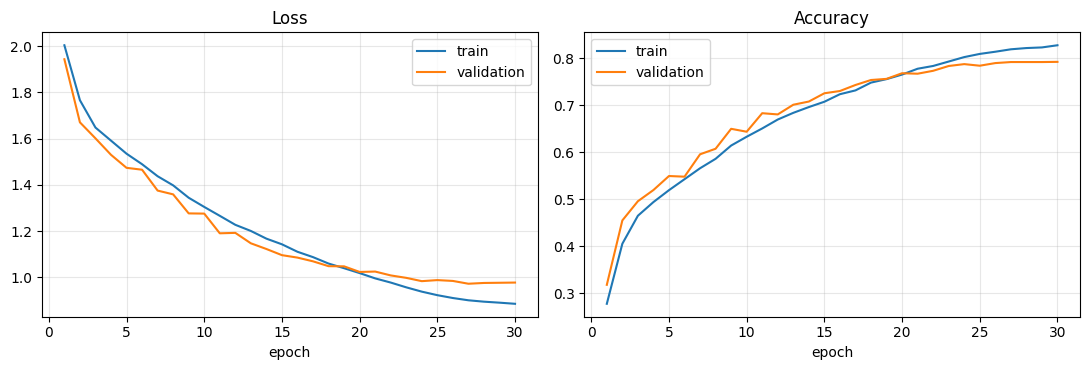

In [ ]:
# Training curves
if history["train_loss"]:
    ep = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(ep, history["train_loss"], label="train"); ax[0].plot(ep, history["val_loss"], label="validation")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(ep, history["train_acc"], label="train"); ax[1].plot(ep, history["val_acc"], label="validation")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

In [ ]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

y_true, y_pred = predict_all(model, test_loader)
test_acc = (y_true == y_pred).mean()
print(f"TEST ACCURACY: {test_acc*100:.2f}%  ({int((y_true == y_pred).sum())}/{len(y_true)} correct)\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

TEST ACCURACY: 79.91%  (7991/10000 correct)

              precision    recall  f1-score   support

    airplane      0.807     0.825     0.816      1000
  automobile      0.862     0.898     0.880      1000
        bird      0.762     0.744     0.753      1000
         cat      0.714     0.569     0.633      1000
        deer      0.799     0.727     0.761      1000
         dog      0.699     0.747     0.722      1000
        frog      0.835     0.847     0.841      1000
       horse      0.779     0.879     0.826      1000
        ship      0.876     0.872     0.874      1000
       truck      0.845     0.883     0.864      1000

    accuracy                          0.799     10000
   macro avg      0.798     0.799     0.797     10000
weighted avg      0.798     0.799     0.797     10000



### Test-set audit and uncertainty

The test-set metric below is computed from predictions of the **loaded best-validation checkpoint**, not used for checkpoint selection. Accuracy alone is insufficient: per-class precision/recall and the confusion matrix reveal unequal class performance. A 95% Wilson interval provides a sampling-uncertainty summary, not a guarantee about distribution shift.

In [ ]:
# Requires running the preceding test-set prediction cell in this kernel.
from collections import Counter
from math import sqrt
import numpy as np

assert len(y_true) == len(y_pred) == 10_000, "Expected all 10,000 official test images"
assert np.issubdtype(np.asarray(y_true).dtype, np.integer)
assert np.all((0 <= y_true) & (y_true < 10))
assert np.all((0 <= y_pred) & (y_pred < 10))
counts = np.bincount(y_true, minlength=10)
assert np.array_equal(counts, np.full(10, 1000)), f"Unexpected test class counts: {counts}"
correct = int(np.count_nonzero(y_true == y_pred))
accuracy = correct / len(y_true)
print(f"INDEPENDENT TEST EVALUATION: {correct}/10000 = {accuracy:.2%}")
if correct == 7991:
    print("PASS: independently computed test accuracy matches the historical 79.91% report")
else:
    print("DISCREPANCY: independent accuracy does not match the historical 79.91% report")
    print("Check checkpoint identity, test transforms, dataset ordering, and model.eval().")
# Descriptive Wilson interval, assuming approximately independent test cases.
z = 1.96; sample_n = len(y_true); phat = accuracy
center = (phat + z*z/(2*sample_n)) / (1 + z*z/sample_n)
margin = z * sqrt(phat*(1-phat)/sample_n + z*z/(4*sample_n**2)) / (1+z*z/sample_n)
print(f"Descriptive 95% Wilson interval: {center-margin:.2%} to {center+margin:.2%}")
assert np.isclose(test_acc, accuracy), "Accuracy differs from the evaluation cell"
print("PASS: recomputed accuracy matches the evaluation cell")


INDEPENDENT TEST EVALUATION: 7991/10000 = 79.91%
PASS: independently computed test accuracy matches the historical 79.91% report
Descriptive 95% Wilson interval: 79.11% to 80.68%
PASS: recomputed accuracy matches the evaluation cell


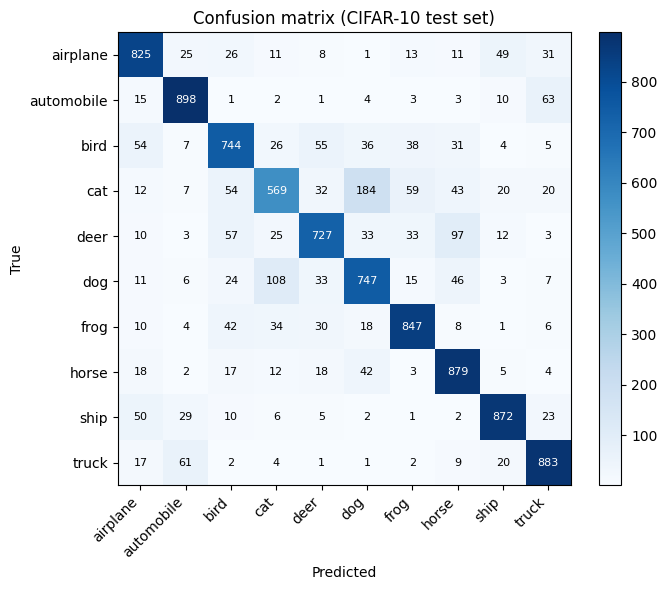

Best class : automobile (89.8%)
Worst class: cat (56.9%)


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (CIFAR-10 test set)")
plt.tight_layout(); plt.show()

per_class = cm.diagonal() / cm.sum(1)
print("Best class :", CLASSES[per_class.argmax()], f"({per_class.max()*100:.1f}%)")
print("Worst class:", CLASSES[per_class.argmin()], f"({per_class.min()*100:.1f}%)")

### Qualitative error analysis — real test-set failures

The gallery below is constructed from **the test-set predictions just computed**, not manually selected example images or invented labels. To make the selection deterministic and reduce cherry-picking, it selects the first available error in each true class, then fills remaining positions from the earliest unused errors. Each panel shows the original image, ground truth, prediction, and the model's softmax confidence. **Confidence is not calibrated probability of correctness.** The confidence values are obtained by a second inference pass on the selected images; the selection is based on the original full-test predictions.

Total misclassified test images: 2009


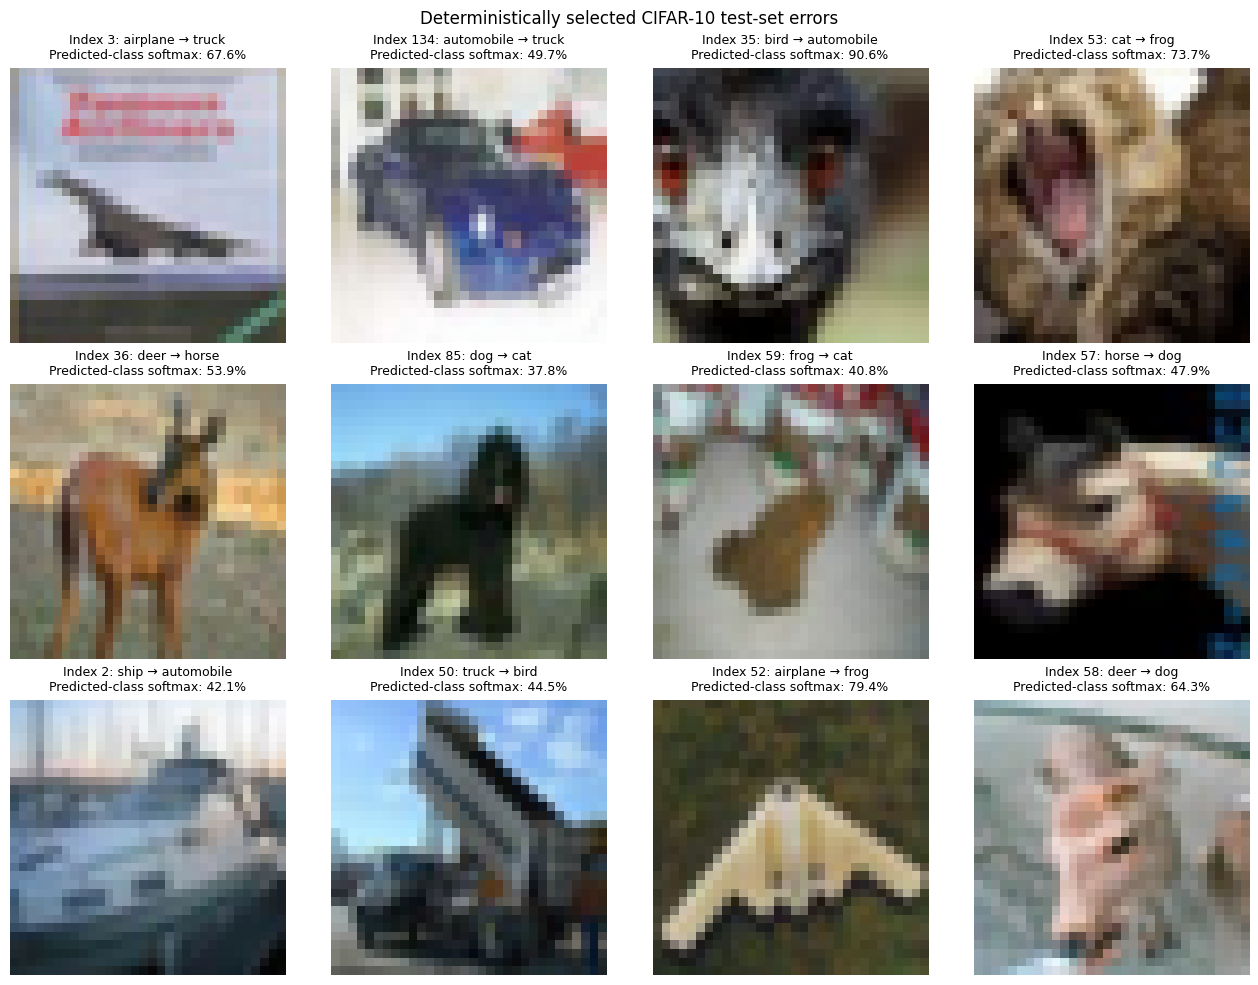

Displayed indices: [3, 134, 35, 53, 36, 85, 59, 57, 2, 50, 52, 58]


In [ ]:
# Deterministic, auditable failure-case gallery (requires fresh test predictions).
errors = np.flatnonzero(y_true != y_pred)
print(f"Total misclassified test images: {len(errors)}")
if len(errors) == 0:
    print("No errors to display.")
else:
    selected = []
    for cls in range(len(CLASSES)):
        match = next((int(i) for i in errors if int(y_true[i]) == cls), None)
        if match is not None:
            selected.append(match)
    selected.extend(int(i) for i in errors if int(i) not in selected)
    selected = selected[:12]
    xb = torch.stack([test_ds[i][0] for i in selected]).to(device)
    model.eval()
    with torch.inference_mode():
        probabilities = model(xb).softmax(dim=1).cpu().numpy()
    fig, axes = plt.subplots(3, 4, figsize=(13, 10))
    for ax, k in zip(axes.flat, range(12)):
        if k >= len(selected):
            ax.axis("off"); continue
        i = selected[k]
        pred = int(y_pred[i]); true = int(y_true[i])
        # Assert the second pass agrees with the full-test prediction.
        assert int(probabilities[k].argmax()) == pred, f"Prediction mismatch at index {i}"
        ax.imshow(denorm(test_ds[i][0]).permute(1, 2, 0))
        ax.set_title(f"Index {i}: {CLASSES[true]} → {CLASSES[pred]}\n"
                     f"Predicted-class softmax: {probabilities[k,pred]:.1%}", fontsize=9)
        ax.axis("off")
    plt.suptitle("Deterministically selected CIFAR-10 test-set errors")
    plt.tight_layout(); plt.show()
    print("Displayed indices:", selected)

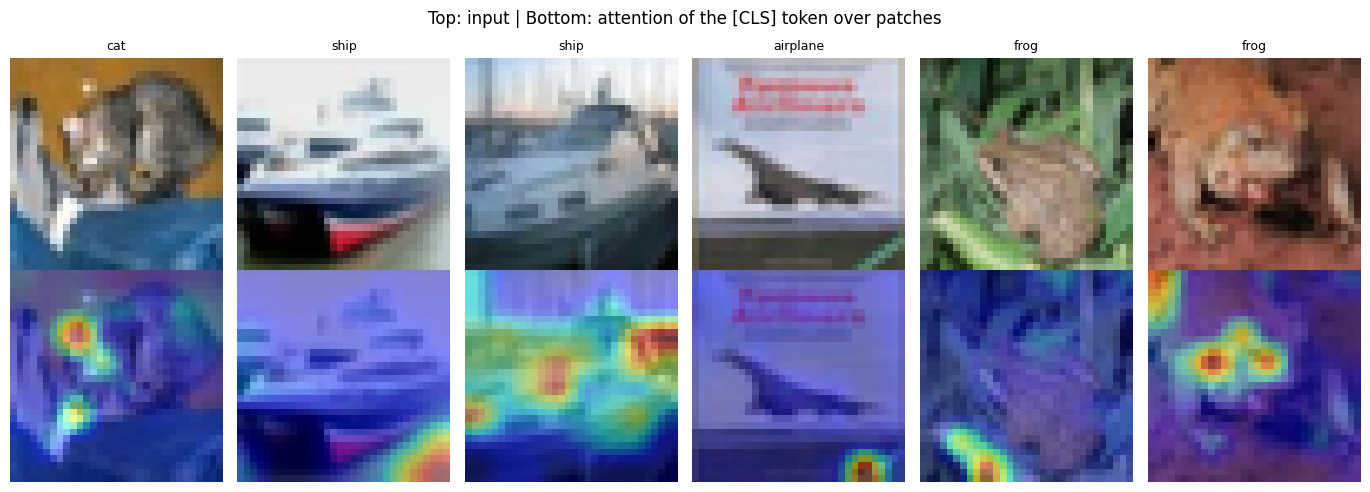

In [ ]:
# What does the [CLS] token look at? (attention from [CLS] to each patch, last encoder block)
model.eval()
idx = [0, 1, 2, 3, 4, 5]
xb = torch.stack([test_ds[i][0] for i in idx]).to(device)
att = model.cls_attention(xb).cpu()
g = CFG["IMG_SIZE"] // CFG["PATCH_SIZE"]
fig, axes = plt.subplots(2, len(idx), figsize=(2.3 * len(idx), 5))
for k, i in enumerate(idx):
    a = att[k].reshape(1, 1, g, g)
    a = F.interpolate(a, size=CFG["IMG_SIZE"], mode="bilinear", align_corners=False)[0, 0]
    axes[0, k].imshow(denorm(xb[k]).permute(1, 2, 0)); axes[0, k].set_title(CLASSES[test_ds[i][1]], fontsize=9)
    axes[1, k].imshow(denorm(xb[k]).permute(1, 2, 0)); axes[1, k].imshow(a, cmap="jet", alpha=0.45)
    axes[0, k].axis("off"); axes[1, k].axis("off")
plt.suptitle("Top: input | Bottom: attention of the [CLS] token over patches"); plt.tight_layout(); plt.show()

### Quantitative training-dynamics analysis

The checkpoint stores epoch-level training/validation loss and accuracy. The analysis below uses those **recorded measurements**; it does not estimate new performance. In particular, it distinguishes the final training–validation accuracy gap from evidence of overfitting: a gap alone does not prove overfitting, and training-time augmentation and dropout make train and validation metrics non-identical evaluation conditions.

Training time is taken from the preserved original console log, not remeasured here. The model was selected using validation accuracy; the test set must not be used for checkpoint selection.

In [ ]:
# Recorded checkpoint history only: descriptive statistics, not a new training run.
if not checkpoint_file.is_file():
    print("Checkpoint missing: training-dynamics audit unavailable.")
else:
    h = torch.load(checkpoint_file, map_location="cpu", weights_only=True)["history"]
    assert len(h["val_acc"]) == CFG["EPOCHS"], (
        f"Expected {CFG['EPOCHS']} epochs, got {len(h['val_acc'])}; check checkpoint path."
    )
    epochs_logged = len(h["val_acc"])
    best_epoch = int(np.argmax(h["val_acc"])) + 1
    gap_pp = 100 * (h["train_acc"][-1] - h["val_acc"][-1])
    print(f"Recorded epochs: {epochs_logged}")
    print(f"Best validation accuracy: {max(h['val_acc'])*100:.2f}% (epoch {best_epoch})")
    print(f"First → final training accuracy: {h['train_acc'][0]*100:.2f}% → {h['train_acc'][-1]*100:.2f}%")
    print(f"First → final validation accuracy: {h['val_acc'][0]*100:.2f}% → {h['val_acc'][-1]*100:.2f}%")
    print(f"Final train–validation accuracy gap: {gap_pp:.2f} percentage points")
    print(f"Final train/validation loss: {h['train_loss'][-1]:.3f} / {h['val_loss'][-1]:.3f}")
    print("Preserved original log: ~29,159 s (8.10 h) for 30 epochs on its recorded environment")

Recorded epochs: 30
Best validation accuracy: 79.22% (epoch 30)
First → final training accuracy: 27.76% → 82.75%
First → final validation accuracy: 31.80% → 79.22%
Final train–validation accuracy gap: 3.53 percentage points
Final train/validation loss: 0.885 / 0.977
Preserved original log: ~29,159 s (8.10 h) for 30 epochs on its recorded environment


### Per-class error analysis and interpretation

The preserved classification report (1,000 test examples per class) records **automobile recall of 89.8%** and **cat recall of 56.9%**—a 32.9-percentage-point difference. Cat precision is 71.4%, versus cat recall of 56.9%: the model misses substantially more true cats than its precision alone might suggest. Dog recall is 74.7%, and bird recall is 74.4%. These are **historical metrics from the saved report**, not independently regenerated by this commentary.

This performance heterogeneity is consistent with the difficulty of discriminating fine-grained animal shapes and textures at 32×32 resolution, but it does **not** establish a particular confusion pair or a causal explanation. The exact most-confused class pairs must be computed from the test-set confusion matrix. The following cell does so from `cm`, which is generated by the notebook's existing evaluation pipeline.

In [ ]:
# Derived from the confusion matrix computed from the current test predictions.
if "cm" not in globals():
    print("Run the test prediction and confusion-matrix cells first.")
else:
    assert cm.shape == (len(CLASSES), len(CLASSES))
    assert int(cm.sum()) == len(y_true) == 10000
    off_diag = cm.copy()
    np.fill_diagonal(off_diag, 0)
    pairs = sorted(((int(off_diag[i, j]), CLASSES[i], CLASSES[j])
                    for i in range(len(CLASSES))
                    for j in range(len(CLASSES)) if i != j), reverse=True)
    print("Most frequent directional errors (true class → predicted class):")
    for count, true_class, pred_class in pairs[:5]:
        print(f"  {true_class} → {pred_class}: {count} / 1,000")
    recalls = np.diag(cm) / cm.sum(axis=1)
    print(f"Class recall range: {recalls.min():.1%} to {recalls.max():.1%}")
    assert int(np.trace(cm)) == int((y_true == y_pred).sum())
    print("PASS: confusion-matrix counts agree with current test predictions")

Most frequent directional errors (true class → predicted class):
  cat → dog: 184 / 1,000
  dog → cat: 108 / 1,000
  deer → horse: 97 / 1,000
  automobile → truck: 63 / 1,000
  truck → automobile: 61 / 1,000
Class recall range: 56.9% to 89.8%
PASS: confusion-matrix counts agree with current test predictions


## Discussion: Interpretation, Uncertainty, and Limitations

**What the results establish.** The original run recorded 7,991 correct predictions out of 10,000 CIFAR-10 test images (79.91% top-1 accuracy). Treating the test cases as approximately independent draws, the **descriptive 95% Wilson binomial interval** is approximately **79.11%–80.68%**. This interval reflects finite test-sample uncertainty only; it does not quantify variability across training seeds, architectures, datasets, or hardware. A single-run result cannot establish a statistically significant advantage over another model.

**Training behavior.** The checkpoint's 30-epoch history shows validation accuracy increasing from 31.80% to 79.22%; the final recorded training accuracy is 82.75%. The final training–validation accuracy gap is approximately 3.53 percentage points. The validation loss is approximately 0.977 at epoch 30, versus training loss of 0.885. These measurements suggest convergence with a modest generalization gap; they do not prove that a longer run would improve test performance.

**Class-level failure modes.** The saved classification report reveals pronounced differences in class recall, particularly between automobiles and cats. A rigorous follow-up would examine directional confusion counts and representative failures from the *current* predictions. Because no matched baseline, multiple-seed experiment, or robustness test was conducted, explanations involving visual similarity, sample efficiency, or inductive bias remain hypotheses rather than experimentally isolated causes.

**Interpretability.** The visualization displays the last encoder block's `[CLS]`-to-patch attention, averaged over heads. It is **not attention rollout**, a saliency ground truth, or a causal feature attribution. A bright region indicates attention allocation, not necessarily the region that determined the classification.

**Efficiency and generalization.** This implementation has 2,693,578 learned parameters and 65 tokens per image. The preserved training log reports approximately 29,159 seconds (~8.10 hours) for 30 epochs on its recorded CPU environment; hardware, software, and batch settings must be matched before comparing training efficiency. No measured patch-size ablation, CNN comparison, or pretrained-ViT comparison is claimed. Future controlled work should fix the data split and training budget, repeat multiple random seeds, and report accuracy, runtime, memory, and uncertainty.

**Reproducibility boundary.** Checkpoint-key compatibility and training-history integrity can be verified without downloading CIFAR-10. Independently validating the 79.91% test accuracy requires the exact checkpoint, evaluation preprocessing, and all 10,000 held-out test images. The notebook's existing test evaluation and confusion-matrix cells perform that check when run in order.

**Model selection and execution.** The best checkpoint is selected using validation accuracy, while the official test split is reserved for final evaluation. The live demonstration uses the original checkpoint with `CFG["RETRAIN"] = False`; a shortened `TRAIN_SUBSET` smoke test cannot be compared with the recorded full-data training run. Reproduction requires compatible Python/PyTorch/torchvision and scientific Python packages, the same preprocessing and split, and the checkpoint or full retraining. Hardware-specific GPU operations may not be bitwise deterministic.


## 7. Summary and Conclusion

This project implemented a Vision Transformer in PyTorch for CIFAR-10 classification, including patch embedding, multi-head self-attention, Transformer encoder blocks, and a `[CLS]` classification head.

**Key results:** The original run recorded **79.22% best validation accuracy** and **79.91% test accuracy** over the official 10,000-image test set. The notebook provides executable checkpoint loading, live inference, class-level evaluation, and error visualizations. The historical test result must be checked against fresh test predictions before it is described as independently reproduced.

**Conclusion:** Image patch tokens and self-attention can support image classification without a conventional convolutional feature extractor. Results vary by class, and last-layer `[CLS]` attention is a visualization of attention allocation rather than a causal explanation of the prediction. The limitations and proposed follow-up experiments are discussed above.